In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Path to the original dataset
DATA_PATH = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:

# Inspect column names, data types, and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:

# View summary statistics for numerical columns
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:

# Count missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Check for completely duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check whether customer IDs are duplicated
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# Check blank strings, especially in TotalCharges
blank_total_charges = (
    df["TotalCharges"].astype(str).str.strip().eq("").sum()
)

print("Blank TotalCharges values:", blank_total_charges)


Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0
Duplicate customer IDs: 0
Blank TotalCharges values: 11


In [6]:

# Find rows where TotalCharges contains blank strings
blank_mask = df["TotalCharges"].str.strip().eq("")

# Display the affected customers
df.loc[
    blank_mask,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [7]:

# Inspect the distribution of tenure for customers with blank TotalCharges
print("Tenure values for affected customers:")
print(df.loc[blank_mask, "tenure"].value_counts())

# Inspect their monthly charges
print("\nMonthly charges for affected customers:")
print(df.loc[blank_mask, "MonthlyCharges"].describe())


Tenure values for affected customers:
tenure
0    11
Name: count, dtype: int64

Monthly charges for affected customers:
count    11.000000
mean     41.418182
std      23.831484
min      19.700000
25%      20.125000
50%      25.750000
75%      58.975000
max      80.850000
Name: MonthlyCharges, dtype: float64


Churn
No     5174
Yes    1869
Name: count, dtype: int64


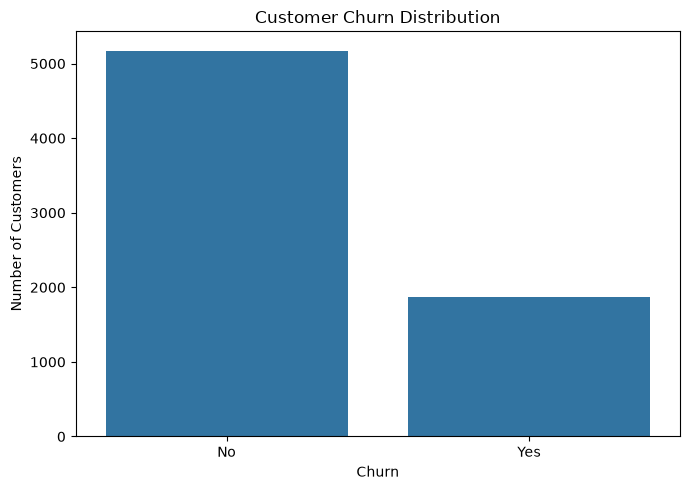


Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [8]:

# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

print(churn_counts)

# Plot churn distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Calculate percentages
print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))


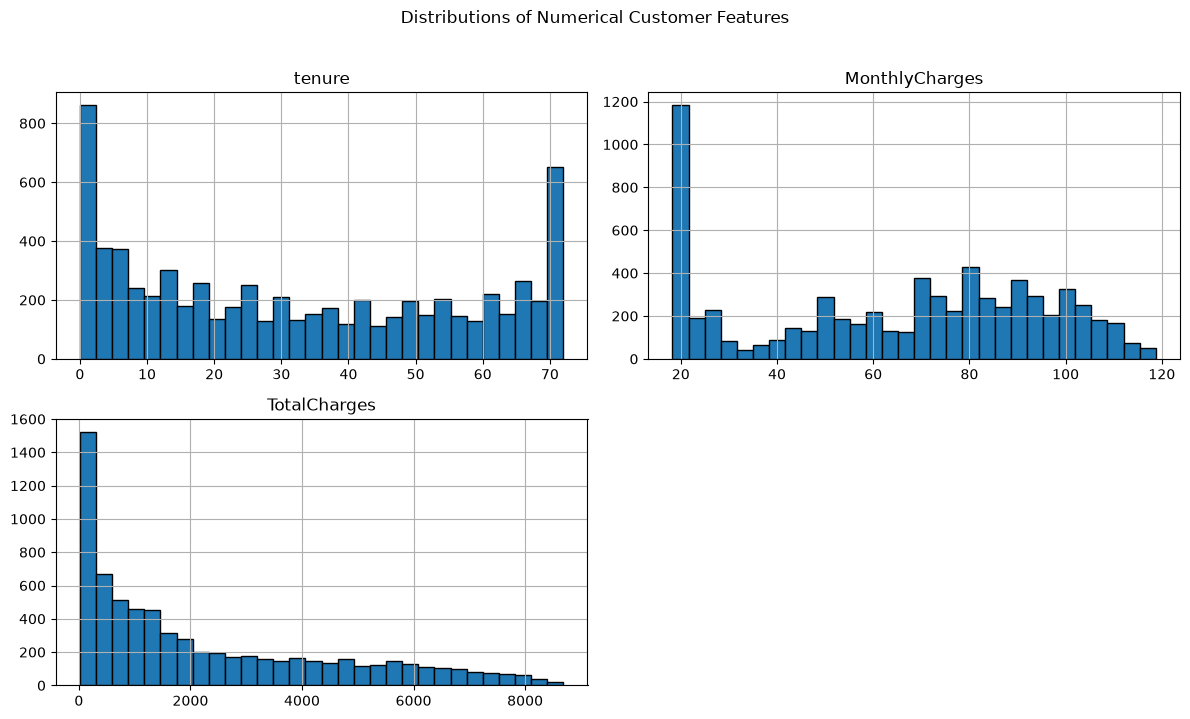

In [9]:

# Convert TotalCharges temporarily for EDA only
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"].str.strip().replace("", np.nan),
    errors="coerce"
)

# Create a temporary numerical view
numeric_eda = df[["tenure", "MonthlyCharges"]].copy()
numeric_eda["TotalCharges"] = total_charges_numeric

# Visualize the distributions
numeric_eda.hist(figsize=(12, 7), bins=30, edgecolor="black")
plt.suptitle("Distributions of Numerical Customer Features", y=1.02)
plt.tight_layout()
plt.show()


In [10]:

# Select categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Exclude customerID because it is an identifier, not a category to analyze
categorical_columns.remove("customerID")

print("Categorical columns:", len(categorical_columns))
print(categorical_columns)


Categorical columns: 17
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


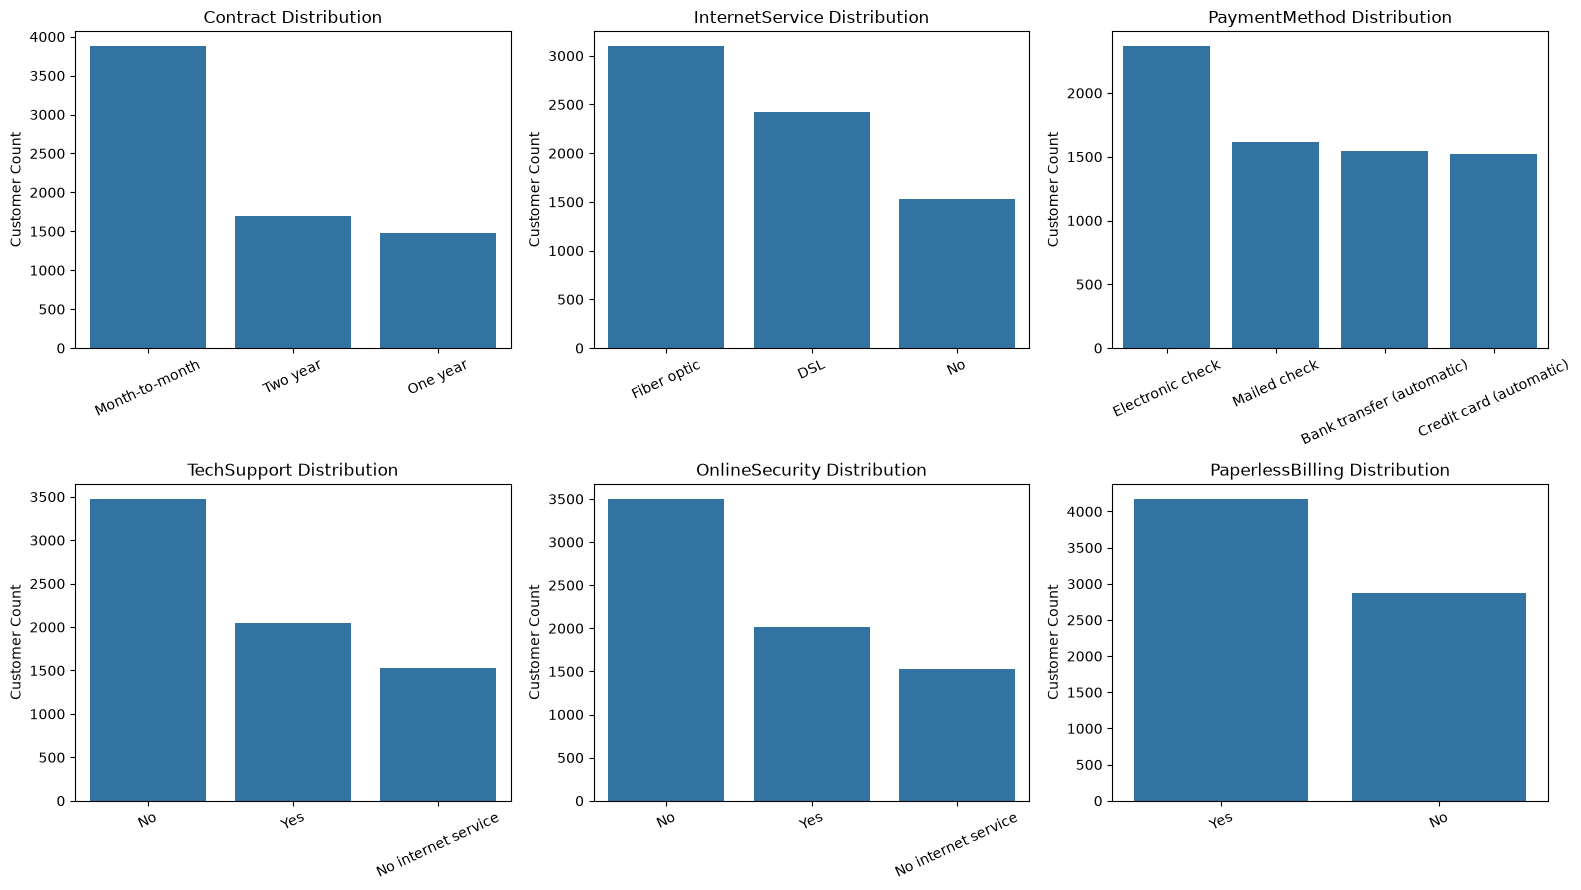

In [13]:

# Select categorical features worth exploring
features_to_plot = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling"
]

# Create a grid of subplots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, column in zip(axes, features_to_plot):
    order = df[column].value_counts().index

    sns.countplot(
        data=df,
        x=column,
        order=order,
        ax=ax
    )

    ax.set_title(f"{column} Distribution")
    ax.set_xlabel("")
    ax.set_ylabel("Customer Count")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()



Churn rate by Contract (%):
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


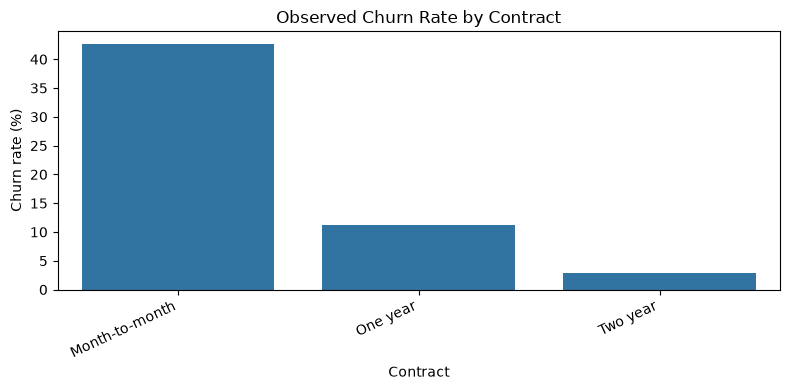


Churn rate by InternetService (%):
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


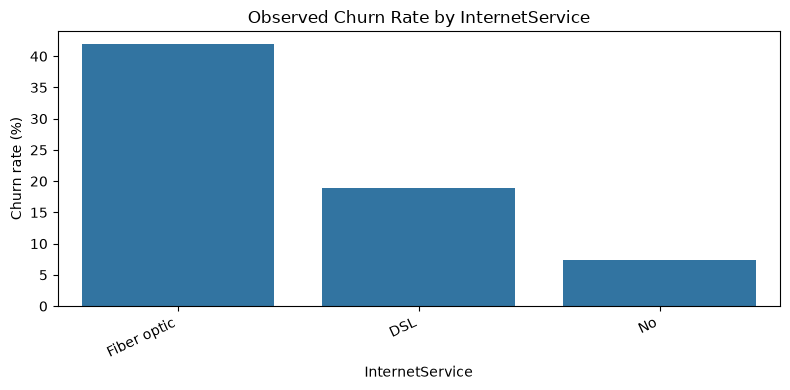


Churn rate by PaymentMethod (%):
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


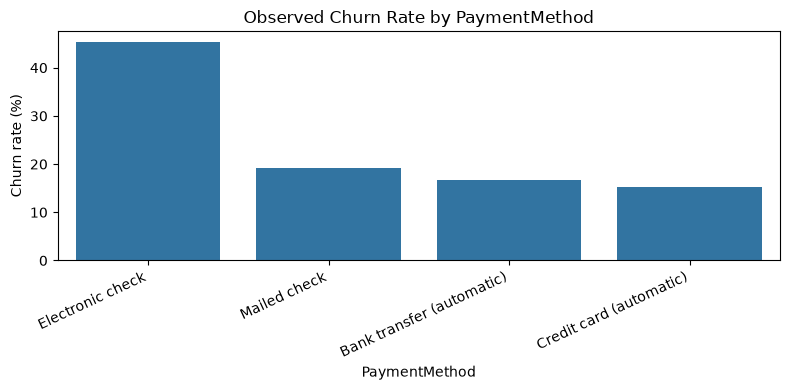

In [12]:

# Calculate the churn rate within each category
features_to_compare = [
    "Contract",
    "InternetService",
    "PaymentMethod"
]

for column in features_to_compare:
    churn_rate = (
        df.groupby(column, observed=True)["Churn"]
        .apply(lambda values: (values == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\nChurn rate by {column} (%):")
    print(churn_rate.round(2))

    plt.figure(figsize=(8, 4))
    sns.barplot(x=churn_rate.index, y=churn_rate.values)
    plt.title(f"Observed Churn Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Churn rate (%)")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


1. Contract type shows the strongest difference
- Month-to-month: 42.71%
- One year: 11.27%
- Two year: 2.83%
Customers on month-to-month contracts have a much higher observed churn rate. Contract commitment is an important feature to investigate when interpreting clusters.












2. Internet service is associated with different churn rates
- Fiber optic: 41.89%
- DSL: 18.96%
- No internet service: 7.40%
Fiber-optic customers have a higher observed churn rate. This doesn't establish why they leave; pricing, service experience, and other variables may also matter.












3. Payment method also shows a notable difference
- Electronic check: 45.29%
- Mailed check: 19.11%
- Automatic bank transfer: 16.71%
- Automatic credit card: 15.24%
Electronic-check customers have a much higher observed churn rate than customers using automatic payments. We'll investigate whether this pattern aligns with the clusters later.

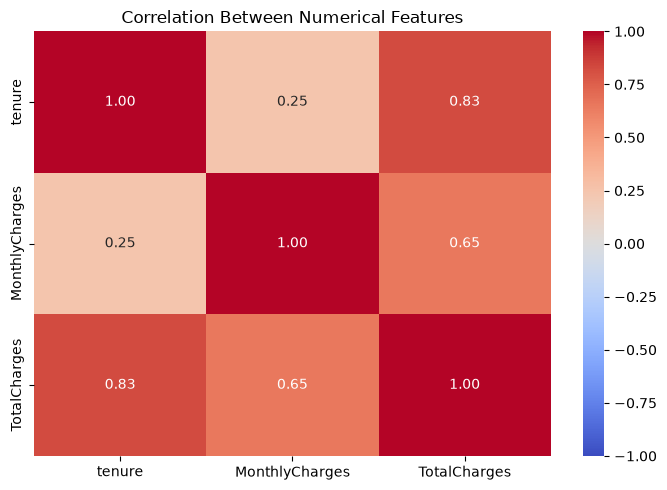

,tenure,MonthlyCharges,TotalCharges
tenure,1.00000,0.247900,0.825880
MonthlyCharges,0.24790,1.000000,0.651065
TotalCharges,0.82588,0.651065,1.000000


In [15]:

# Create a temporary numerical dataset for EDA
eda_numeric = df[["tenure", "MonthlyCharges"]].copy()

eda_numeric["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip().replace("", np.nan),
    errors="coerce"
)

# Correlation between numerical features
correlation = eda_numeric.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

correlation


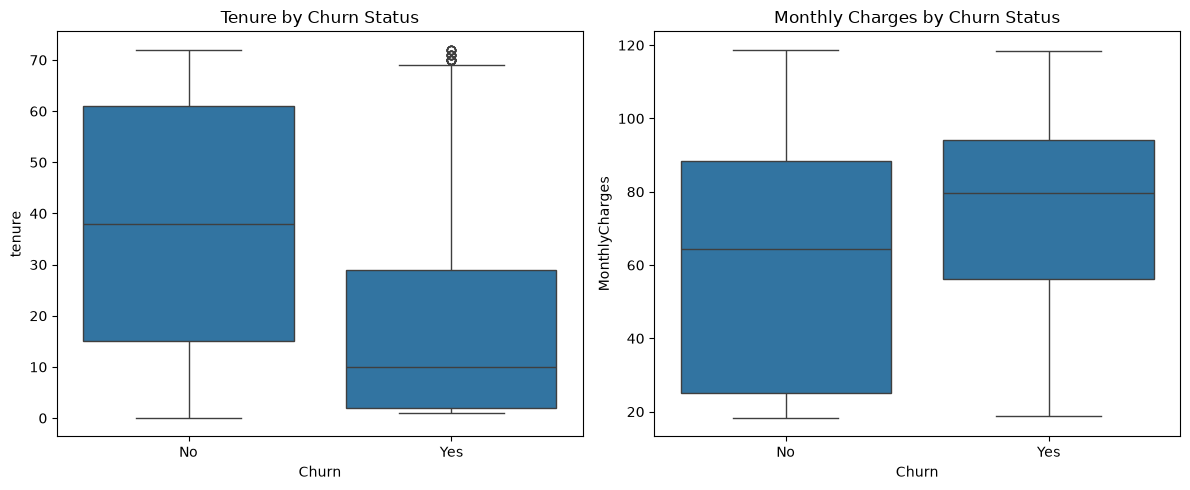

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    ax=axes[0]
)
axes[0].set_title("Tenure by Churn Status")

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    ax=axes[1]
)
axes[1].set_title("Monthly Charges by Churn Status")

plt.tight_layout()
plt.show()


In [18]:

print("DATA QUALITY SUMMARY")
print("-" * 35)

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

print(
    "Blank TotalCharges:",
    df["TotalCharges"].str.strip().eq("").sum()
)

print("\nCategorical feature cardinality:")
print(df.select_dtypes(include=["object", "str"]).nunique())


DATA QUALITY SUMMARY
-----------------------------------
Dataset shape: (7043, 21)
Duplicate rows: 0
Duplicate customer IDs: 0
Blank TotalCharges: 11

Categorical feature cardinality:
customerID          7043
gender                 2
Partner                2
Dependents             2
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
TotalCharges        6531
Churn                  2
dtype: int64


## Summary and Key Findings

### Dataset Overview
- 7,043 customers and 21 columns.
- No duplicate rows or duplicate customer IDs.

### Data Quality
- 11 blank `TotalCharges` values, all associated with customers whose tenure is zero.
- `TotalCharges` requires conversion from text to numeric.

### Key Insights
- Overall observed churn rate: 26.54%.
- Month-to-month contracts have a higher observed churn rate than longer contracts.
- Customers who churned have shorter median tenure and higher median monthly charges.
- `tenure` and `TotalCharges` are strongly correlated (0.826).

### Implications for Clustering
- Exclude `customerID` because it is an identifier.
- Exclude `Churn` from clustering features and use it later to interpret the resulting segments.
- Investigate feature selection and scaling before clustering.

### Next Steps
Proceed to data cleaning, categorical encoding, and numerical feature scaling in `02_preprocessing.ipynb`.